In [ ]:
## IMPORTANT RUN this jupyer notebook needs the scbeducation.py file ran first. It NEEEDS the scb_2024.csv 


import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

s = pd.read_csv("scb_2024.csv", dtype={"Yrke2012": str})
cols = {"Yrke2012": "occupation", "Yrke2012_name": "occupation_name",
        "UtbinriktnSUN2020": "education", "UtbinriktnSUN2020_name": "education_name"}
df = s.groupby(list(cols), as_index=False)["count"].sum().rename(columns={**cols, "count": "employees"})
print(len(df), df["employees"].sum())

4300 5006642


In [24]:
d = df[~df["education"].isin([0, 9])]
p = d.pivot_table(index="occupation_name", columns="education_name", values="employees", aggfunc="sum")
p = p[p.sum(axis=1) >= 1000]
X = p.div(p.sum(axis=1), axis=0)

for k in range(3, 15):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    print(k, round(silhouette_score(X, km.labels_), 3))

3 0.407
4 0.397
5 0.424
6 0.441
7 0.462
8 0.48
9 0.455
10 0.451
11 0.461
12 0.425
13 0.412
14 0.415


In [25]:
km = KMeans(n_clusters=8, n_init=10, random_state=0).fit(X)
X["cluster"] = km.labels_
size = p.sum(axis=1)

profile = X.groupby("cluster").mean()
for c in range(8):
    top = size[X["cluster"] == c].nlargest(5).index
    print(c, profile.loc[c].idxmax(), round(profile.loc[c].max(), 2), "|", ", ".join(top))

0 Engineering,  manufacturing and construction 0.68 | Software- and system developers, Engineering professionals in electrical, electronics and telecommunications, Woodworkers, carpenters, Machine-tool operators, Electricians, installation and service
1 Health and welfare 0.82 | Assistant nurses, home care and homes for the elderly, Child care workers, Personal care providers, Professional nurses, Assistant nurses, hospital ward
2 Humanities and art 0.49 | Graphic designers, Musicians, singers and composers, Game and digital media designers, Fashion designers and related professionals, Film, stage and related directors and producers
3 Education science and teacher training 0.77 | Primary school teachers, Preschool teachers, Secondary education teachers, Teaching professionals not elsewhere classified, Recreation leaders
4 Social sciences, law and business administration  0.74 | Economic assistants, Accounting associate professionals, Personnel and human resources specialist, Advertisin

In [26]:
names = {0:"Engineering", 1:"Health", 2:"Humanities", 3:"Education", 4:"Social sci/business", 5:"Mixed / no clear field", 6:"Services", 7:"Agriculture"}
X["cluster_name"] = X["cluster"].map(names)
print((size.groupby(X["cluster_name"]).sum() / size.sum() * 100).sort_values().round(1))

cluster_name
Agriculture                0.9
Humanities                 1.3
Services                   3.7
Education                  7.2
Social sci/business        9.9
Health                    16.9
Engineering               24.1
Mixed / no clear field    36.1
dtype: float64


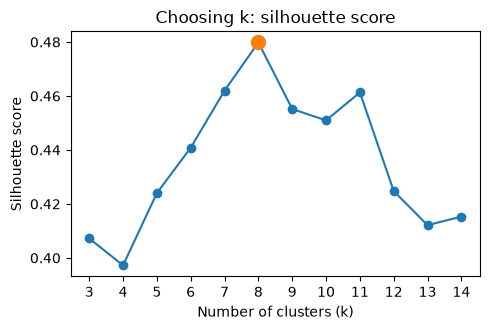

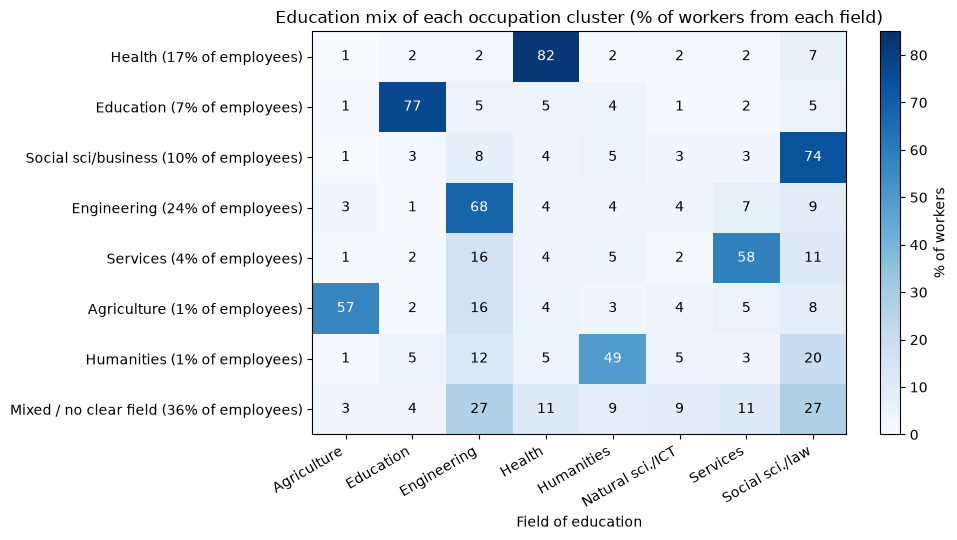

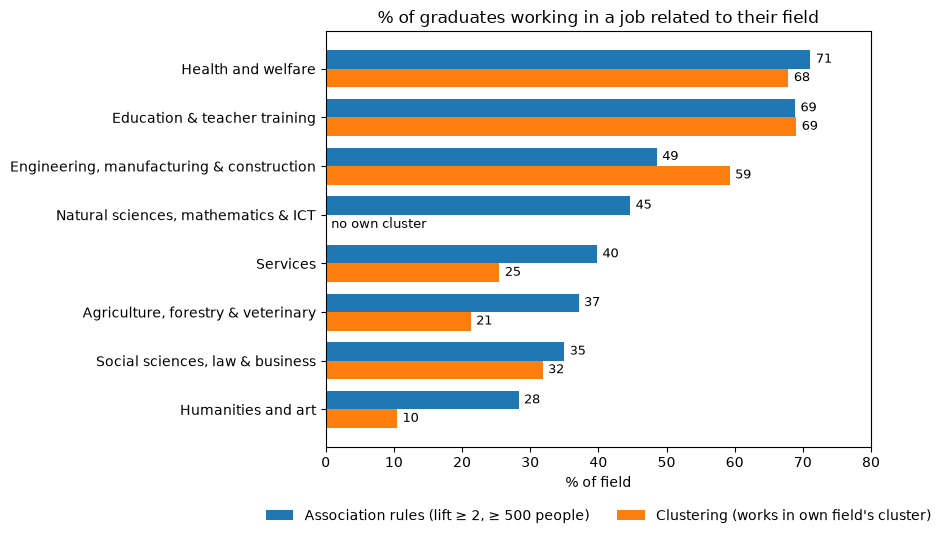

In [27]:
import numpy as np
import matplotlib.pyplot as plt

F = X[p.columns]   # the 8 field % columns
short = dict(zip(p.columns, ["Agriculture", "Education", "Engineering", "Health",
                             "Humanities", "Natural sci./ICT", "Services", "Social sci./law"]))

# Plot silhouette score per k
ks = range(3, 15)
sil = [silhouette_score(F, KMeans(n_clusters=k, n_init=10, random_state=0).fit(F).labels_) for k in ks]
plt.figure(figsize=(5, 3.4))
plt.plot(ks, sil, marker="o")
plt.plot(8, max(sil), marker="o", color="tab:orange", ms=10)
plt.xticks(ks); plt.xlabel("Number of clusters (k)"); plt.ylabel("Silhouette score")
plt.title("Choosing k: silhouette score")
plt.tight_layout(); plt.savefig("silhouette_k.png", dpi=200); plt.show()

# Plot heatmap: education mix of each cluster
profile = F.groupby(X["cluster_name"]).mean() * 100
profile = profile.loc[profile.max(axis=1).sort_values(ascending=False).index]   # clearest first, mixed last
emp = size.groupby(X["cluster_name"]).sum() / size.sum() * 100
plt.figure(figsize=(10, 5.5))
plt.imshow(profile, cmap="Blues", aspect="auto", vmin=0, vmax=85)
for i in range(8):
    for j in range(8):
        v = profile.iloc[i, j]
        plt.text(j, i, f"{v:.0f}", ha="center", va="center", color="white" if v > 45 else "black")
plt.yticks(range(8), [f"{c} ({emp[c]:.0f}% of employees)" for c in profile.index])
plt.xticks(range(8), [short[f] for f in profile.columns], rotation=30, ha="right")
plt.xlabel("Field of education"); plt.colorbar(label="% of workers")
plt.title("Education mix of each occupation cluster (% of workers from each field)")
plt.tight_layout(); plt.savefig("cluster_heatmap.png", dpi=200); plt.show()

# Plot two methods: % of graduates in a related job
# association: lift >= 2 and >= 500 people
a = d.copy()
field_tot = a.groupby("education_name")["employees"].transform("sum")
occ_tot = a.groupby("occupation")["employees"].transform("sum")
a["lift"] = (a["employees"] / field_tot) / (occ_tot / a["employees"].sum())
related = a[(a["lift"] >= 2) & (a["employees"] >= 500)]
assoc = related.groupby("education_name")["employees"].sum() / a.groupby("education_name")["employees"].sum() * 100
# clustering: works in own field's cluster (field is top and > 40%)
own = {c: profile.loc[c].idxmax() for c in profile.index if profile.loc[c].max() > 40}
clus = pd.Series({f: p.loc[X["cluster_name"] == c, f].sum() / p[f].sum() * 100 for c, f in own.items()})
clus = clus.reindex(assoc.index).fillna(0)

long = dict(zip(p.columns, ["Agriculture, forestry & veterinary", "Education & teacher training",
                            "Engineering, manufacturing & construction", "Health and welfare", "Humanities and art",
                            "Natural sciences, mathematics & ICT", "Services", "Social sciences, law & business"]))
o = assoc.sort_values().index
y = np.arange(8); h = 0.38
plt.figure(figsize=(9, 5.5))
plt.barh(y + h/2, assoc[o], h, label="Association rules (lift ≥ 2, ≥ 500 people)")
plt.barh(y - h/2, clus[o], h, label="Clustering (works in own field's cluster)")
for i, f in enumerate(o):
    plt.text(assoc[f] + 0.8, i + h/2, f"{assoc[f]:.0f}", va="center", fontsize=9)
    plt.text(clus[f] + 0.8, i - h/2, f"{clus[f]:.0f}" if clus[f] > 0 else "no own cluster", va="center", fontsize=9)
plt.yticks(y, [long[f] for f in o]); plt.xlim(0, 80); plt.xlabel("% of field")
plt.title("% of graduates working in a job related to their field")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
plt.tight_layout(); plt.savefig("related_job_two_methods.png", dpi=200, bbox_inches="tight"); plt.show()

